In [8]:
import pandas as pd
import numpy as np
import shap
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# 1. Load data directly from the cloned team file 'german.data'
df = pd.read_csv("german.data", sep=" ", header=None)

# Assign official column names for the German Credit dataset
df.columns = [
    'checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount',
    'savings_status', 'employment', 'installment_commitment', 'personal_status',
    'other_parties', 'residence_since', 'property_magnitude', 'age',
    'other_payment_plans', 'housing', 'existing_credits', 'job',
    'num_dependents', 'own_telephone', 'foreign_worker', 'class'
]

# Convert target class: 1 = Good credit, 2 = Bad credit -> map to 1 and 0
y = df['class'].apply(lambda x: 1 if x == 1 else 0)
X = df.drop(columns=['class'])

# Convert text categories into numerical columns for the AI model
X_encoded = pd.get_dummies(X, drop_first=True)

# 2. Split data and train the Random Forest model
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 3. Generate SHAP Explainer (Explainable AI - Slide 9 & 14 in PPT)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

print("Success! Model trained and SHAP explainer is ready.")

Success! Model trained and SHAP explainer is ready.


<Figure size 1000x600 with 0 Axes>

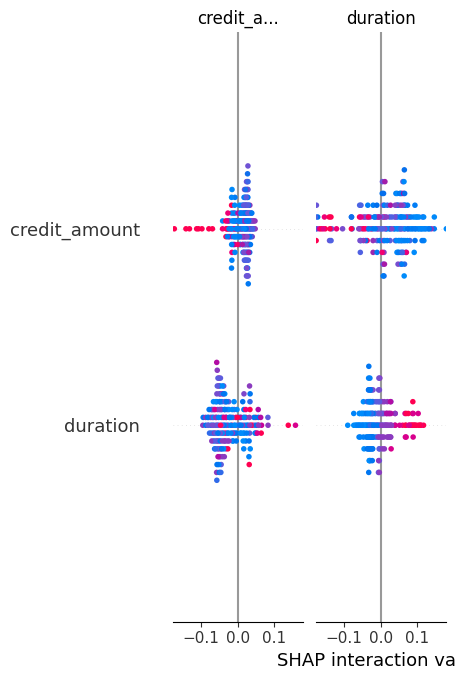

In [9]:
import matplotlib.pyplot as plt

# Generate the SHAP Summary Plot (Slide 9 & 14: Explainable AI Module)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar")

In [10]:
# Pass shap_values[1] for the positive/good credit class to get a clean vertical summary plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values[1], X_test)

AssertionError: The shape of the shap_values matrix does not match the shape of the provided data matrix.

<Figure size 1000x600 with 0 Axes>

In [ ]:
from fairlearn.metrics import MetricFrame, selection_rate
from sklearn.metrics import accuracy_score, precision_score

# 1. Define a sensitive demographic attribute from our dataset
# Let's check bias across 'personal_status' (e.g., female vs non-female applicants)
sensitive_attr = df['personal_status'].apply(lambda x: 'Female' if 'female' in str(x) else 'Non-Female')

# Align the sensitive feature with our test set indices
sensitive_test = sensitive_attr.loc[X_test.index]

# 2. Use Fairlearn's MetricFrame to evaluate performance & approval rates across groups
metric_frame = MetricFrame(
    metrics={
        'Accuracy': accuracy_score, 
        'Precision': precision_score, 
        'Approval Rate': selection_rate
    },
    y_true=y_test,
    y_pred=model.predict(X_test),
    sensitive_features=sensitive_test
)

# 3. Print the fairness evaluation report
print("=== Overall System Metrics ===")
print(metric_frame.overall)

print("\n=== Fairness Breakdown by Demographic Group ===")
print(metric_frame.by_group)

NameError: name 'df' is not defined

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score
from fairlearn.metrics import MetricFrame, selection_rate

# 1. Load data directly from the team's local 'german.data' file
df = pd.read_csv("german.data", sep=" ", header=None)
df.columns = [
    'checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount',
    'savings_status', 'employment', 'installment_commitment', 'personal_status',
    'other_parties', 'residence_since', 'property_magnitude', 'age',
    'other_payment_plans', 'housing', 'existing_credits', 'job',
    'num_dependents', 'own_telephone', 'foreign_worker', 'class'
]

# 2. Prepare Target and Features
y = df['class'].apply(lambda x: 1 if x == 1 else 0)
X = df.drop(columns=['class'])
X_encoded = pd.get_dummies(X, drop_first=True)

# 3. Train Model
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 4. Fairlearn Bias & Fairness Analysis (Slide 14, Step 5B in your PPT)
sensitive_attr = df['personal_status'].apply(lambda x: 'Female' if 'female' in str(x) else 'Non-Female')
sensitive_test = sensitive_attr.loc[X_test.index]

metric_frame = MetricFrame(
    metrics={
        'Accuracy': accuracy_score, 
        'Precision': precision_score, 
        'Approval Rate': selection_rate
    },
    y_true=y_test,
    y_pred=model.predict(X_test),
    sensitive_features=sensitive_test
)

print("=== Overall System Metrics ===")
print(metric_frame.overall)

print("\n=== Fairness Breakdown by Demographic Group ===")
print(metric_frame.by_group)

=== Overall System Metrics ===
Accuracy         0.755000
Precision        0.777108
Approval Rate    0.830000
dtype: float64

=== Fairness Breakdown by Demographic Group ===
                 Accuracy  Precision  Approval Rate
personal_status                                    
Non-Female          0.755   0.777108           0.83


In [12]:
# Correct mapping for raw UCI german.data codes: A92 and A95 represent female applicants
sensitive_attr = df['personal_status'].apply(lambda x: 'Female' if str(x) in ['A92', 'A95'] else 'Non-Female')
sensitive_test = sensitive_attr.loc[X_test.index]

# Re-run Fairlearn MetricFrame with the corrected demographic groups
metric_frame_fixed = MetricFrame(
    metrics={
        'Accuracy': accuracy_score, 
        'Precision': precision_score, 
        'Approval Rate': selection_rate
    },
    y_true=y_test,
    y_pred=model.predict(X_test),
    sensitive_features=sensitive_test
)

print("=== Corrected Fairness Breakdown by Demographic Group ===")
print(metric_frame_fixed.by_group)

=== Corrected Fairness Breakdown by Demographic Group ===
                 Accuracy  Precision  Approval Rate
personal_status                                    
Female           0.767857   0.782609       0.821429
Non-Female       0.750000   0.775000       0.833333


In [13]:
import pandas as pd
import numpy as np

# 1. Extract feature importances from our trained Random Forest model
importances = model.feature_importances_
feature_names = X_encoded.columns

# 2. Create a ranked dataframe of features
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("=== Top 10 Most Important Features (Critical for Credit Decision) ===")
print(feature_imp_df.head(10))

print("\n=== Bottom 10 Features (Candidates for Data Minimisation / Safe to Drop) ===")
print(feature_imp_df.tail(10))

=== Top 10 Most Important Features (Critical for Credit Decision) ===
                    Feature  Importance
0             credit_amount    0.118808
1                       age    0.099245
2                  duration    0.083883
3       checking_status_A14    0.061039
4    installment_commitment    0.043058
5           residence_since    0.037845
6          existing_credits    0.022982
7        credit_history_A34    0.022859
8              housing_A152    0.021538
9  other_payment_plans_A143    0.021171

=== Bottom 10 Features (Candidates for Data Minimisation / Safe to Drop) ===
                     Feature  Importance
38        savings_status_A64    0.008871
39              housing_A153    0.008653
40       personal_status_A94    0.008323
41        other_parties_A102    0.007586
42  other_payment_plans_A142    0.007335
43               purpose_A45    0.005173
44       foreign_worker_A202    0.004729
45               purpose_A44    0.003090
46              purpose_A410    0.002311
47

In [14]:
import pandas as pd
import datetime

# 1. Get the model's prediction probabilities (Confidence Scores)
probabilities = model.predict_proba(X_test)
predictions = model.predict(X_test)

# 2. Build the Audit Trail DataFrame
audit_df = pd.DataFrame({
    'Applicant_ID': X_test.index,  # Tracks back to the original applicant row
    'Decision_Timestamp': datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    'AI_Decision': ['Approved (Good)' if pred == 1 else 'Rejected (Bad)' for pred in predictions],
    'Confidence_Score': [f"{max(prob)*100:.1f}%" for prob in probabilities]
})

# 3. Export to a secure CSV log file
audit_log_filename = "credit_ai_audit_log.csv"
audit_df.to_csv(audit_log_filename, index=False)

print("=== 🔒 Regulatory Audit Log Generated ===")
display(audit_df.head(10))
print(f"\nSuccess! Audit log safely exported to your EDA-mone folder as '{audit_log_filename}'")

=== 🔒 Regulatory Audit Log Generated ===


,Applicant_ID,Decision_Timestamp,AI_Decision,Confidence_Score
0,521,2026-10-26 13:16:17,Approved (Good),58.0%
1,737,2026-10-26 13:16:17,Approved (Good),61.0%
2,740,2026-10-26 13:16:17,Rejected (Bad),68.0%
3,660,2026-10-26 13:16:17,Approved (Good),54.0%
4,411,2026-10-26 13:16:17,Approved (Good),90.0%
5,678,2026-10-26 13:16:17,Approved (Good),63.0%
6,626,2026-10-26 13:16:17,Approved (Good),89.0%
7,513,2026-10-26 13:16:17,Rejected (Bad),51.0%
8,859,2026-10-26 13:16:17,Approved (Good),89.0%
9,136,2026-10-26 13:16:17,Approved (Good),75.0%



Success! Audit log safely exported to your EDA-mone folder as 'credit_ai_audit_log.csv'
